# TP 2 - Construire l'auto-attention pas à pas

Objectif : partir d'une moyenne des tokens précédents et arriver à une tête qui apprend elle-même quels tokens comptent.

Les quatre versions : boucles -> produit matriciel -> masque + Softmax -> self-attention.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

## Étape 1 - Agréger par produit matriciel

In [2]:
torch.manual_seed(42)

# matrice triangulaire basse
a = torch.tril(torch.ones(3, 3))
# chaque ligne est divisée par sa somme
a = a / torch.sum(a, 1, keepdim=True)

# 3 vecteurs de dimension 2
b = torch.randint(0, 10, (3, 2)).float()

# chaque ligne de c = moyenne pondérée des lignes de b
c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [3]:
# c2 à la main : moyenne des deux premières lignes de b
print((b[0] + b[1]) / 2)
print(c[1])

tensor([4.0000, 5.5000])
tensor([4.0000, 5.5000])


**Calcul de c2 sans Python :** la deuxième ligne de `a` vaut (1/2, 1/2, 0), donc c2 = (b1 + b2) / 2 = ((2, 7) + (6, 4)) / 2 = (4 ; 5,5). Le troisième vecteur ne compte pas, et le résultat est identique à `c[1]`.

**Pourquoi chaque ligne de `a` somme-t-elle à 1 ?** Parce qu'on la divise par sa propre somme. Le produit donne 
 une moyenne pondérée.

## Étape 2 - Moyenner uniquement le passé (version 1 : boucles)

In [4]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2          # batch, temps, canaux
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):                 # chaque séquence
    for t in range(T):             # chaque position
        xprev = x[b, :t+1]         # forme (t+1, C) : passé + token courant
        xbow[b, t] = torch.mean(xprev, dim=0)

print(x[0])
print(xbow[0])

tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])


**Formes de `xprev` :** (1, 2) pour t = 0, (4, 2) pour t = 3 et (8, 2) pour t = 7.

**Vérification :** la première ligne de `xbow[0]` est identique à celle de `x[0]`. La deuxième est la moyenne des deux premières, soit (−0,0894 ; −0,4926).

**Pourquoi `dim=0` ?** La dimension 0 est le temps. On moyenne sur les tokens visibles et on garde les C composantes séparées.

## Étape 3 - Version 2 : produit matriciel

In [5]:
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)   # poids égaux sur le passé

xbow2 = wei @ x                        # (T,T) @ (B,T,C) -> (B,T,C)
print(torch.allclose(xbow, xbow2, atol=1e-6))
print(wei)

True
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])


## Étape 4 - Version 3 : masque + Softmax

In [6]:
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))   # on cache le futur
wei = F.softmax(wei, dim=-1)                      # chaque ligne somme à 1

xbow3 = wei @ x
print(torch.allclose(xbow, xbow3, atol=1e-6))
print(wei)

True
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])


**Résultat :** les deux tests `torch.allclose` renvoient `True` et les deux matrices `wei` affichées sont les mêmes. Les versions 1, 2 et 3 sont donc équivalentes.

**Pourquoi `wei @ x` fonctionne-t-il avec (T, T) et (B, T, C) ?** PyTorch diffuse `wei` sur la dimension batch (broadcasting). Le produit se fait sur les deux dernières dimensions : (T, T) @ (T, C) donne (T, C), pour chacune des B séquences.

**Que devient Softmax aux emplacements à −∞ ?** exp(−∞) = 0, donc le poids est nul. Les scores restants valent tous 0 et se partagent le poids à parts égales.

## Étape 5 - Version 4 : self-attention

Les poids ne sont plus fixés à 1/(t+1) : ils viennent de la compatibilité entre queries et keys.

Ici les lignes de `wei` correspondent aux queries. Dans les diapos du cours elles sont en colonnes, la matrice est donc transposée.

In [7]:
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16                      # d_h

# trois projections linéaires apprises
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)                          # (B, T, 16)
q = query(x)                        # (B, T, 16)
wei = q @ k.transpose(-2, -1)       # (B, T, T) : scores query / key
wei = wei * head_size**-0.5         # mise à l'échelle
wei = wei.masked_fill(tril == 0, float('-inf'))   # pas d'accès au futur
wei = F.softmax(wei, dim=-1)        # scores -> poids

v = value(x)                        # (B, T, 16)
out = wei @ v                       # (B, T, 16) : mélange des values

print(out.shape)
print(wei[0])

torch.Size([4, 8, 16])
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5124, 0.4876, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2361, 0.2073, 0.5566, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2141, 0.1465, 0.5219, 0.1175, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1772, 0.1684, 0.2309, 0.2516, 0.1720, 0.0000, 0.0000, 0.0000],
        [0.1318, 0.1948, 0.1391, 0.1463, 0.1958, 0.1923, 0.0000, 0.0000],
        [0.1356, 0.0573, 0.4062, 0.0976, 0.1091, 0.1435, 0.0507, 0.0000],
        [0.1083, 0.1771, 0.0855, 0.1267, 0.1177, 0.2036, 0.0867, 0.0944]],
       grad_fn=<SelectBackward0>)


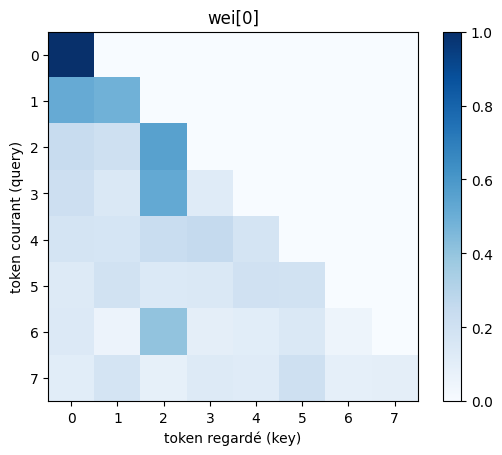

tensor([0.1083, 0.1771, 0.0855, 0.1267, 0.1177, 0.2036, 0.0867, 0.0944],
       grad_fn=<SelectBackward0>)
tensor([0.0949, 0.1157, 0.1658, 0.2089, 0.1443, 0.0801, 0.0843, 0.1061],
       grad_fn=<SelectBackward0>)


In [8]:
# affichage de wei[0]
plt.imshow(wei[0].detach(), cmap="Blues")
plt.colorbar()
plt.xlabel("token regardé (key)")
plt.ylabel("token courant (query)")
plt.title("wei[0]")
plt.show()

# les poids dépendent maintenant du contenu : ils changent d'une séquence à l'autre
print(wei[0, -1])
print(wei[1, -1])

**Lecture de `wei[0]` :**
- la matrice est triangulaire : aucun token ne regarde le futur ;
- les poids ne sont plus égaux sur une ligne. Le token d'indice 2 reçoit un poids élevé depuis lui-même (0,56) et depuis les tokens 3 (0,52) et 6 (0,41) ;
- pour le dernier token, le poids le plus fort va au token 5 (0,20), alors que dans `wei[1]` il va au token 3 (0,21). Les poids dépendent donc du contenu de la séquence.

Les couches ne sont pas entraînées et `x` est aléatoire : ces poids n'ont pas encore de signification.

**Quelle ligne de `wei[0]` correspond au dernier token ?** La dernière, `wei[0, -1]` (indice 7). C'est la seule qui peut regarder les 8 tokens.

**Pourquoi mélanger `v` et non `k` ?** La key sert à être comparée aux queries, la value contient l'information transmise. Les séparer permet au modèle d'apprendre deux choses différentes : quand un token est pertinent, et ce qu'il apporte.

## Étape 6 - Stabiliser Softmax

In [9]:
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)

raw = q @ k.transpose(-2, -1)        # sans mise à l'échelle
scaled = raw * head_size**-0.5       # divisé par racine de d_h

print(raw.var(), scaled.var())

z = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print(torch.softmax(z, dim=-1))      # poids assez répartis
print(torch.softmax(z * 8, dim=-1))  # une valeur domine

tensor(19.8478) tensor(1.2405)
tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


**Variances :** on obtient 19,85 sans mise à l'échelle et 1,24 après division par √d_h. En théorie on attend d_h = 16 puis 1 ; l'écart vient du petit échantillon (256 scores). Le rapport entre les deux vaut bien 16, soit d_h.

**Effet sur Softmax :** quand les scores sont multipliés par 8, le plus grand poids passe de 0,29 à 0,80. Softmax se rapproche d'un choix unique, les autres tokens ne contribuent presque plus et les gradients deviennent faibles.

## Bilan - Vérifications

In [10]:
# wei et out viennent de l'étape 5

# 1) chaque ligne somme à 1
print(torch.allclose(wei.sum(dim=-1), torch.ones(B, T)))

# 2) aucun poids vers le futur (au-dessus de la diagonale)
print(torch.triu(wei, diagonal=1).abs().max().item())

# 3) forme finale
print(out.shape)

True
0.0
torch.Size([4, 8, 16])


**Résultats des vérifications :**
- chaque ligne de `wei` somme à 1 (`True`) ;
- le plus grand poids vers le futur vaut 0,0 ;
- la sortie `out` a la forme (4, 8, 16), soit (B, T, d_h).

**Formes**

| Symbole / tenseur | Sens | Valeur ou forme |
|---|---|---|
| B | nombre de séquences | 4 |
| T | nombre de tokens par séquence | 8 |
| C | dimension de l'embedding | 32 à l'étape 5 (2 aux étapes 2 à 4) |
| d_h | dimension de la tête | 16 |
| x | entrée | (B, T, C) |
| q, k, v | projections | (B, T, d_h) |
| kᵀ | keys transposées | (B, d_h, T) |
| wei | poids d'attention | (B, T, T) |
| out | sortie | (B, T, d_h) |

**Rôle de Q :** ce que le token courant recherche.

**Rôle de K :** ce que chaque token propose pour être comparé à la query.

**Rôle de V :** l'information transmise, pondérée par les poids d'attention.